In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

In [ ]:
from sklearn.preprocessing import OneHotEncoder ,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OrdinalEncoder
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import ConfusionMatrixDisplay



In [ ]:
df = pd.read_csv('/content/train (1).csv')

In [ ]:
df.head()

,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017/12/23,14:55:37,25.81,26.88,25.50,26.25,12,13,62,45,0.09,0.08,0.09,0.08,535,0.438462,0,0,0
1,2017/12/25,09:31:36,25.06,25.06,24.56,25.38,7,8,38,25,0.07,0.04,0.06,0.11,355,0.000000,0,0,0
2,2017/12/26,07:27:23,25.06,25.06,24.56,25.25,1,1,10,6,0.08,0.05,0.06,0.09,350,0.000000,0,0,0
3,2017/12/22,17:59:35,26.31,26.50,25.94,26.38,148,235,178,10,1.73,0.09,0.17,0.07,930,2.588462,1,1,3
4,2018/01/10,19:23:13,25.63,25.63,25.31,25.69,0,0,0,0,0.07,0.05,0.05,0.09,545,-2.130769,0,0,0


In [ ]:
df.shape

(8103, 19)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8103 entries, 0 to 8102
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  8103 non-null   object 
 1   Time                  8103 non-null   object 
 2   S1_Temp               8103 non-null   float64
 3   S2_Temp               8103 non-null   float64
 4   S3_Temp               8103 non-null   float64
 5   S4_Temp               8103 non-null   float64
 6   S1_Light              8103 non-null   int64  
 7   S2_Light              8103 non-null   int64  
 8   S3_Light              8103 non-null   int64  
 9   S4_Light              8103 non-null   int64  
 10  S1_Sound              8103 non-null   float64
 11  S2_Sound              8103 non-null   float64
 12  S3_Sound              8103 non-null   float64
 13  S4_Sound              8103 non-null   float64
 14  S5_CO2                8103 non-null   int64  
 15  S5_CO2_Slope         

In [ ]:
df.columns

Index(['Date', 'Time', 'S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light',
       'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound',
       'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR',
       'Room_Occupancy_Count'],
      dtype='object')

In [ ]:
df.isna().sum()

,0
Date,0
Time,0
S1_Temp,0
S2_Temp,0
S3_Temp,0
S4_Temp,0
S1_Light,0
S2_Light,0
S3_Light,0
S4_Light,0


In [ ]:
df.describe()

,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
count,8103.000000,8103.000000,8103.000000,8103.000000,8103.000000,8103.000000,8103.000000,8103.000000,8103.00000,8103.000000,8103.000000,8103.000000,8103.000000,8103.000000,8103.000000,8103.000000,8103.000000
mean,25.455803,25.548987,25.058803,25.756451,25.553128,26.128224,34.575589,13.188325,0.16778,0.119435,0.160381,0.104535,462.203505,-0.014135,0.088733,0.079230,0.398618
std,0.353034,0.587229,0.429288,0.357034,51.109283,67.478720,58.963741,19.569448,0.31876,0.263138,0.423869,0.125596,201.211764,1.152688,0.284375,0.270114,0.893659
min,24.940000,24.750000,24.440000,25.000000,0.000000,0.000000,0.000000,0.000000,0.06000,0.040000,0.040000,0.050000,345.000000,-6.296154,0.000000,0.000000,0.000000
25%,25.190000,25.190000,24.690000,25.440000,0.000000,0.000000,0.000000,0.000000,0.07000,0.050000,0.060000,0.060000,355.000000,-0.046154,0.000000,0.000000,0.000000
50%,25.380000,25.380000,24.940000,25.750000,0.000000,0.000000,0.000000,0.000000,0.08000,0.050000,0.060000,0.080000,360.000000,0.000000,0.000000,0.000000,0.000000
75%,25.630000,25.630000,25.380000,26.000000,12.000000,14.000000,50.000000,22.000000,0.08000,0.060000,0.070000,0.100000,470.000000,0.000000,0.000000,0.000000,0.000000
max,26.380000,29.000000,26.190000,26.500000,165.000000,258.000000,280.000000,74.000000,3.88000,3.440000,3.670000,3.400000,1270.000000,8.980769,1.000000,1.000000,3.000000


In [ ]:
df_processed = df.copy()

In [ ]:
df_processed['Room_Occupancy_Count'].value_counts()

,count
Room_Occupancy_Count,
0,6582
2,599
3,555
1,367


In [ ]:
numerical_col = df_processed.select_dtypes(exclude=object).columns

In [ ]:
numerical_col

Index(['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light',
       'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound',
       'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR', 'Room_Occupancy_Count'],
      dtype='object')

In [ ]:
categorical_col = df_processed.select_dtypes(include=object).columns

In [ ]:
categorical_col

Index(['Date', 'Time'], dtype='object')

In [ ]:
df_processed["Date"] = pd.to_datetime(df_processed["Date"])

df_processed["DayOfWeek"] = df_processed["Date"].dt.dayofweek

In [ ]:
df_processed["Time"] = pd.to_datetime(df_processed["Time"])

df_processed["Hour"] = df_processed["Time"].dt.hour

/tmp/ipykernel_814/3891429732.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_processed["Time"] = pd.to_datetime(df_processed["Time"])


In [ ]:
df_processed.columns

Index(['Date', 'Time', 'S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light',
       'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound',
       'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR',
       'Room_Occupancy_Count', 'DayOfWeek', 'Hour'],
      dtype='object')

In [ ]:
scaler_feature_col = ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light',
                    'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound',
                    'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'Hour']

In [ ]:
ordianl_feature = ['DayOfWeek']

In [ ]:
def evaluation_metrics(model_name, y_test, y_pred):

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred , average='macro')
    recall = recall_score(y_test, y_pred , average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')
    confusion_mat = confusion_matrix(y_test, y_pred)

    print(f'Accuracy of {model_name}: {accuracy}')
    print(f'Precision of {model_name}: {precision}')
    print(f'Recall of {model_name}: {recall}')
    print(f'Macro F1 Score of {model_name}: {f1}')
    print(f'Confusion Matrix of {model_name}: \n{confusion_mat}')

In [ ]:
X = df_processed.drop(columns=['Room_Occupancy_Count','Date','Time'])
y = df_processed['Room_Occupancy_Count']

In [ ]:
preprocessed = ColumnTransformer([
    ('numerical',StandardScaler(),scaler_feature_col),
    ('categorical',OrdinalEncoder(),ordianl_feature),
    ('pir', 'passthrough', ['S6_PIR', 'S7_PIR'])
])

In [ ]:
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

X_train_preprocessed = preprocessed.fit_transform(X_train)
X_test_preprocessed = preprocessed.transform(X_test)

In [ ]:
C_values = [0.01, 0.1, 0.5, 1, 2, 5, 10]

for c in C_values:

    model = LogisticRegression(
        C=c,
        class_weight='balanced',
        max_iter=2000
    )

    model.fit(X_train_preprocessed, y_train)

    y_pred = model.predict(X_test_preprocessed)

    score = f1_score(y_test, y_pred, average='macro')

    print("C:", c, "Macro F1:", score)


C: 0.01 Macro F1: 0.957856338380818
C: 0.1 Macro F1: 0.9760314924312786
C: 0.5 Macro F1: 0.9760314924312786
C: 1 Macro F1: 0.9760314924312786
C: 2 Macro F1: 0.9815185807279987
C: 5 Macro F1: 0.9836863129371132
C: 10 Macro F1: 0.9813985635581735


In [ ]:
logistic_model = LogisticRegression(max_iter=2000,C=2,class_weight='balanced')

logistic_model.fit(X_train_preprocessed, y_train)

y_pred = logistic_model.predict(X_test_preprocessed)


In [ ]:
evaluation_metrics('Logistic Regression',y_test,y_pred)

Accuracy of Logistic Regression: 0.9944478716841456
Precision of Logistic Regression: 0.9806034482758621
Recall of Logistic Regression: 0.9828056701348273
Macro F1 Score of Logistic Regression: 0.9815185807279987
Confusion Matrix of Logistic Regression: 
[[1316    0    0    1]
 [   0   73    0    0]
 [   0    0  114    6]
 [   0    0    2  109]]


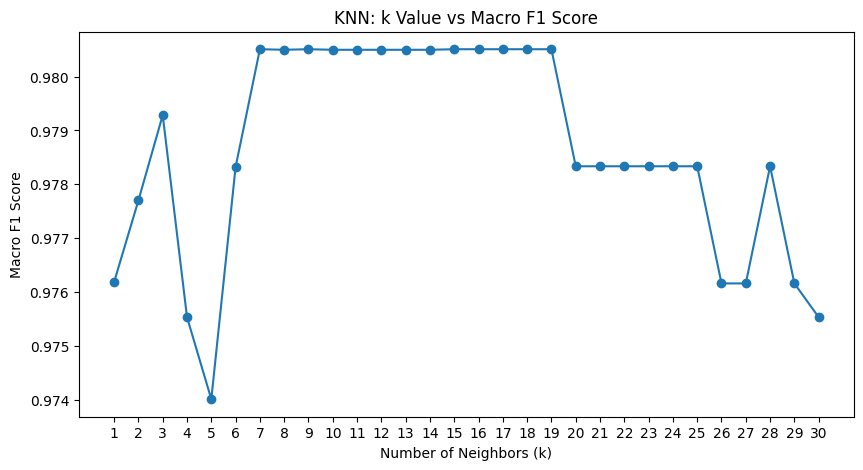

In [ ]:
k_values = range(1, 31)
f1_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_preprocessed, y_train)

    y_pred = knn.predict(X_test_preprocessed)

    score = f1_score(y_test, y_pred, average='macro')
    f1_scores.append(score)

plt.figure(figsize=(10, 5))

plt.plot(k_values, f1_scores, marker='o')

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Macro F1 Score")
plt.title("KNN: k Value vs Macro F1 Score")
plt.xticks(k_values)
plt.show()

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=7)

knn_model.fit(X_train_preprocessed, y_train)

y_pred = knn_model.predict(X_test_preprocessed)



In [ ]:
evaluation_metrics('KNN', y_test, y_pred)

Accuracy of KNN: 0.9944478716841456
Precision of KNN: 0.9804318488529015
Recall of KNN: 0.9807432432432432
Macro F1 Score of KNN: 0.980506329113924
Confusion Matrix of KNN: 
[[1317    0    0    0]
 [   0   73    0    0]
 [   0    0  114    6]
 [   0    0    3  108]]


In [ ]:
for depth in [3, 5, 7, 10, 15, 20, None]:

    dt_model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    dt_model.fit(X_train_preprocessed, y_train)

    y_pred = dt_model.predict(X_test_preprocessed)

    score = f1_score(y_test, y_pred, average='macro')

    print(depth, score)

3 0.8698836872431516
5 0.9642343294249853
7 0.9804829049398247
10 0.9777016575861114
15 0.9842203872389168
20 0.9842203872389168
None 0.9842203872389168


In [ ]:
for leaf in [1, 2, 5, 10, 20, 30, 50]:

    dt_model = DecisionTreeClassifier(
        max_depth=15,
        min_samples_leaf=leaf,
        random_state=42
    )

    dt_model.fit(X_train_preprocessed, y_train)

    y_pred = dt_model.predict(X_test_preprocessed)

    score = f1_score(y_test, y_pred, average='macro')

    print(leaf, score)

1 0.9842203872389168
2 0.9792946544566508
5 0.9771310338458892
10 0.9678171216860518
20 0.9601712520451218
30 0.9228146571037031
50 0.9089318653149886


In [ ]:
for weight in [None, 'balanced']:

    dt_model = DecisionTreeClassifier(
        max_depth=15,
        min_samples_leaf=1,
        class_weight=weight,
        random_state=42
    )

    dt_model.fit(X_train_preprocessed, y_train)

    y_pred = dt_model.predict(X_test_preprocessed)

    score = f1_score(y_test, y_pred, average='macro')

    print(weight, score)

None 0.9842203872389168
balanced 0.98856077241023


In [ ]:
for depth in [5, 7, 10, 15]:
    for leaf in [2, 5, 10, 20]:

        dt_model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            class_weight='balanced',
            random_state=42
        )

        dt_model.fit(X_train_preprocessed, y_train)

        y_pred = dt_model.predict(X_test_preprocessed)

        score = f1_score(y_test, y_pred, average='macro')

        print(
            "depth:", depth,
            "leaf:", leaf,
            "Macro F1:", score
        )

depth: 5 leaf: 2 Macro F1: 0.9709377374195254
depth: 5 leaf: 5 Macro F1: 0.9720760434391207
depth: 5 leaf: 10 Macro F1: 0.9686881268659098
depth: 5 leaf: 20 Macro F1: 0.963216200303607
depth: 7 leaf: 2 Macro F1: 0.9709890345021653
depth: 7 leaf: 5 Macro F1: 0.974354058416585
depth: 7 leaf: 10 Macro F1: 0.9763778088504492
depth: 7 leaf: 20 Macro F1: 0.9650537602833337
depth: 10 leaf: 2 Macro F1: 0.9830483113882442
depth: 10 leaf: 5 Macro F1: 0.9765049044914818
depth: 10 leaf: 10 Macro F1: 0.9763778088504492
depth: 10 leaf: 20 Macro F1: 0.9650537602833337
depth: 15 leaf: 2 Macro F1: 0.9830483113882442
depth: 15 leaf: 5 Macro F1: 0.9765049044914818
depth: 15 leaf: 10 Macro F1: 0.9763778088504492
depth: 15 leaf: 20 Macro F1: 0.9650537602833337


In [ ]:
decision_tree_model = DecisionTreeClassifier(max_depth=15,min_samples_leaf=1,class_weight='balanced',random_state=42)

decision_tree_model.fit(X_train_preprocessed, y_train)

y_pred = decision_tree_model.predict(X_test_preprocessed)



In [ ]:
evaluation_metrics('Decision Tree', y_test, y_pred)

Accuracy of Decision Tree: 0.9969154842689698
Precision of Decision Tree: 0.9878477013432765
Recall of Decision Tree: 0.9894144144144145
Macro F1 Score of Decision Tree: 0.98856077241023
Confusion Matrix of Decision Tree: 
[[1317    0    0    0]
 [   0   73    0    0]
 [   0    1  116    3]
 [   0    0    1  110]]


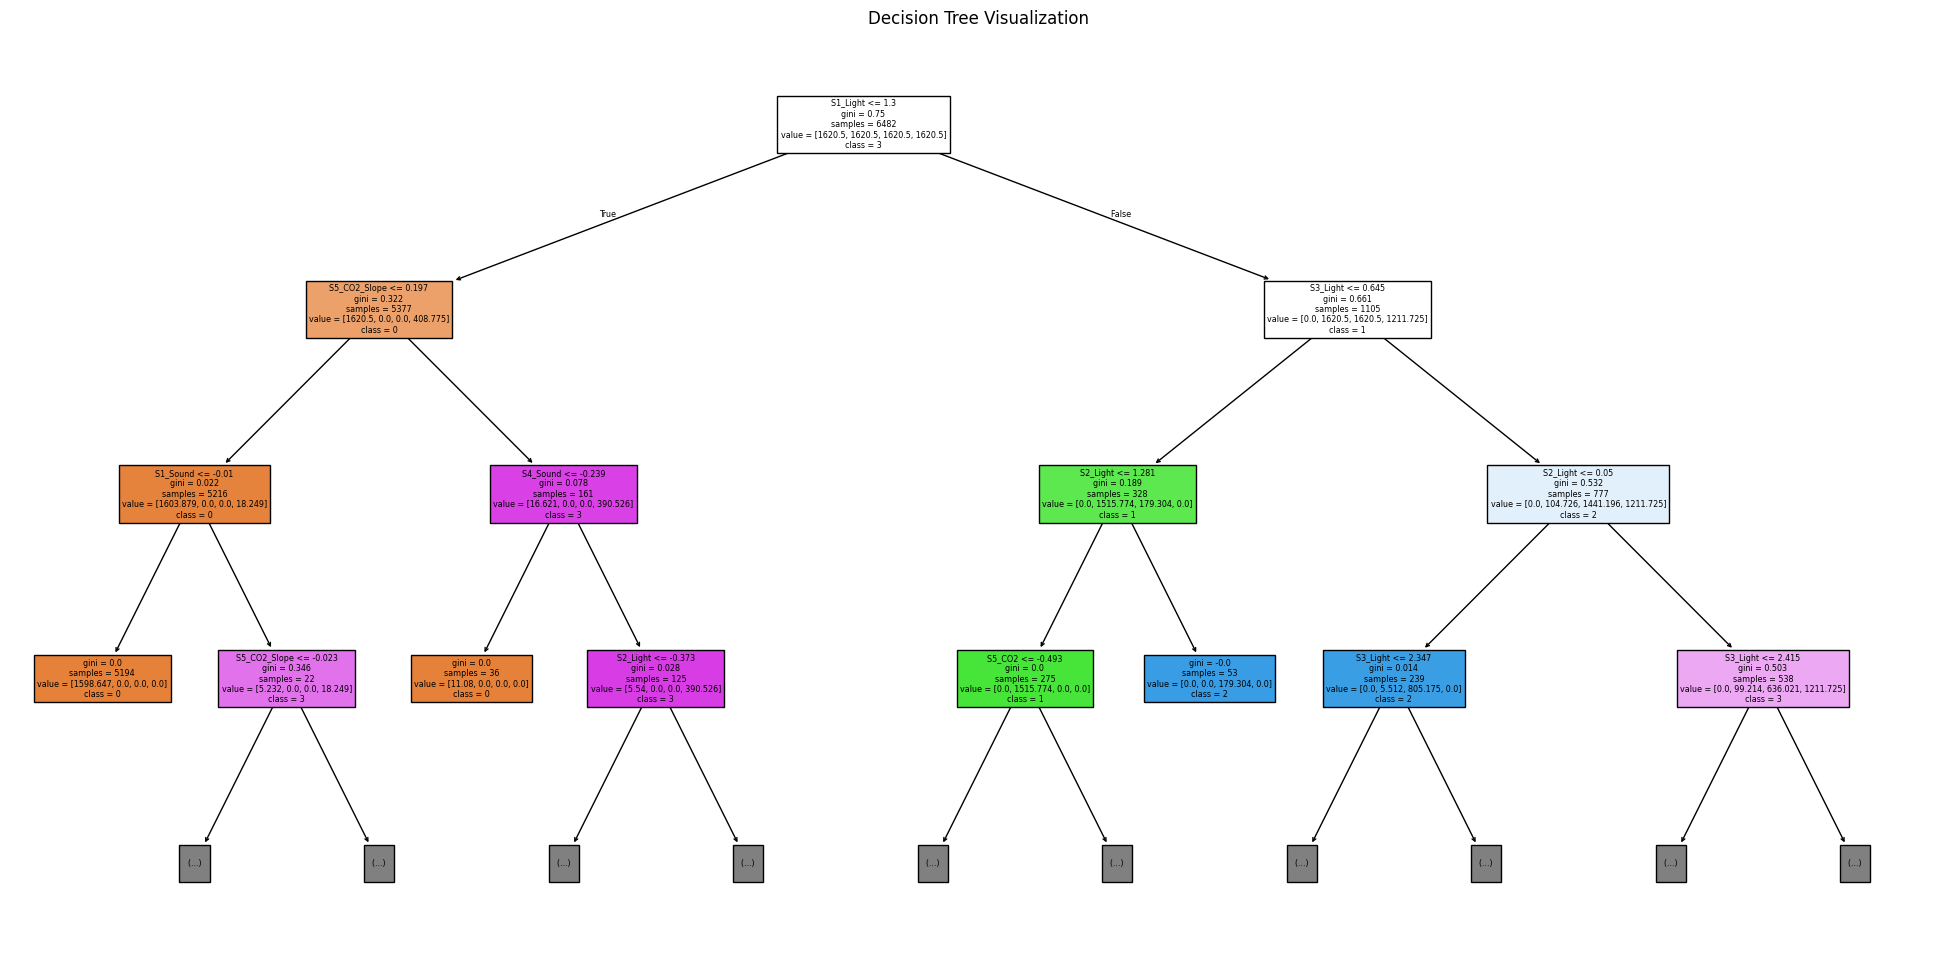

In [ ]:
plt.figure(figsize=(25, 12))

plot_tree(
    decision_tree_model,
    feature_names=X_train.columns,
    class_names=['0', '1', '2', '3'],
    filled=True,
    max_depth=3,

)

plt.title("Decision Tree Visualization")
plt.show()

In [ ]:
test_df = pd.read_csv('/content/test (1).csv')

In [ ]:
test_df.head()

,id,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR
0,ROOM-00001,2017/12/23,14:08:08,26.13,27.13,25.50,26.38,160,247,75,56,0.56,0.90,0.30,0.24,640,1.415385,0,0
1,ROOM-00002,2017/12/23,07:25:17,25.06,25.06,24.44,25.38,1,1,10,6,0.08,0.06,0.06,0.06,355,0.000000,0,0
2,ROOM-00003,2018/01/11,02:46:25,25.19,25.19,24.69,25.25,0,0,0,0,0.07,0.05,0.05,0.08,345,0.000000,0,0
3,ROOM-00004,2017/12/24,03:01:40,25.31,25.31,24.75,25.69,0,0,0,0,0.07,0.05,0.06,0.07,360,-0.096154,0,0
4,ROOM-00005,2017/12/23,19:57:53,26.19,26.00,25.88,26.31,0,0,0,0,0.07,0.05,0.05,0.07,1010,0.896154,0,0


In [ ]:
test_df["Date"] = pd.to_datetime(test_df["Date"])

test_df["DayOfWeek"] = test_df["Date"].dt.dayofweek


In [ ]:
test_df["Time"] = pd.to_datetime(test_df["Time"])

test_df["Hour"] = test_df["Time"].dt.hour

/tmp/ipykernel_814/873428855.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  test_df["Time"] = pd.to_datetime(test_df["Time"])


In [ ]:
test_scaler_feature_col = ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light',
                    'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound',
                    'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'Hour']

In [ ]:
test_ordianl_feature = ['DayOfWeek']

In [ ]:
X_test_df = test_df.drop(columns=['Date','Time'])


In [ ]:
preprocessor_final = ColumnTransformer([
    ('numerical',StandardScaler(),test_scaler_feature_col),
    ('categorical',OrdinalEncoder(),test_ordianl_feature),
    ('pir', 'passthrough', ['S6_PIR', 'S7_PIR'])
])

In [ ]:
X_full_preprocessed = preprocessor_final.fit_transform(X)

In [ ]:
X_final_test = test_df[X.columns]

X_final_test_preprocessed = preprocessor_final.transform(X_final_test)

In [ ]:
final_model = DecisionTreeClassifier(
    max_depth=15,
    min_samples_leaf=1,
    class_weight='balanced',
    random_state=42
)

final_model.fit(X_full_preprocessed, y)

DecisionTreeClassifier(class_weight='balanced', max_depth=15, random_state=42)

In [ ]:
predictions = final_model.predict(X_final_test_preprocessed)

In [ ]:
submission = pd.DataFrame({
    'id': test_df['id'],
    'prediction': predictions
})

In [ ]:
submission.to_csv('predictions.csv', index=False)

In [ ]:
print(submission.shape)
print(submission.columns)
print(submission['prediction'].unique())
print(submission['prediction'].value_counts())

(2026, 2)
Index(['id', 'prediction'], dtype='object')
[2 0 3 1]
prediction
0    1646
2     150
3     138
1      92
Name: count, dtype: int64
